<h1><center>IDATG2208 - Assignment 3</center></h1>

<h3><center>Introduksjon til maskinlæring</h3>

<p><center><strong>Bjørn Ivar Thorsen Høie</strong></center></p>

<p><center>NTNU Gjøvik</center></p>

<p><center>Oktober 2026</center></p>


## Exercise 1

Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6606 - loss: 0.9929 - val_accuracy: 0.7700 - val_loss: 0.6702
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8100 - loss: 0.5551 - val_accuracy: 0.7950 - val_loss: 0.6343
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8433 - loss: 0.4612 - val_accuracy: 0.7950 - val_loss: 0.6239
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8633 - loss: 0.3984 - val_accuracy: 0.8100 - val_loss: 0.6113
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8761 - loss: 0.3485 - val_accuracy: 0.8200 - val_loss: 0.5963
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8922 - loss: 0.3055 - val_accuracy: 0.8200 - val_loss: 0.5981
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9083 - loss: 0.2699 - val_accuracy: 0.8100 - val_loss: 0.6188
Epoch 8/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9172 - loss: 0.2408 - val_accuracy: 0.8050 - val_loss:

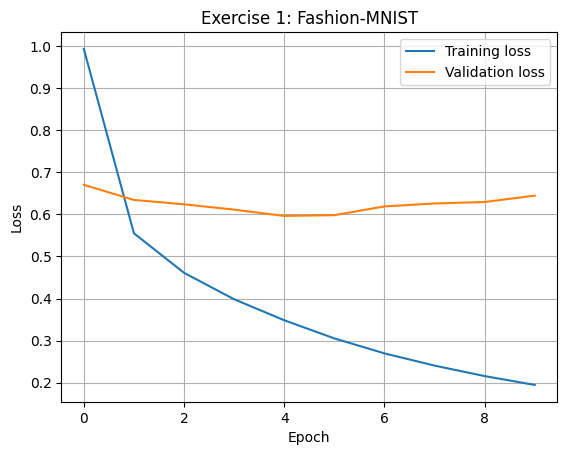

In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# Import data
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()

(X_train_full, y_train_full), (X_test_full, y_test_full) = fashion_mnist
X_train, y_train = X_train_full[:2000] / 255.0, y_train_full[:2000]
X_test,  y_test  = X_test_full[:400]  / 255.0, y_test_full[:400]

tf.keras.utils.set_random_seed(42)

model_exercise_1 = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(10, activation="softmax"),
])

model_exercise_1.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.Nadam(learning_rate=0.001),
              metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)

history = model_exercise_1.fit(X_train, y_train, epochs=50, batch_size=32,
                    validation_split=0.1, callbacks=[early_stop])

test_loss, test_acc = model_exercise_1.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 1: Fashion-MNIST")
plt.legend(); plt.grid(); plt.show()

The test accuracy is: $82.0\%$

## Exercise 2

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.0776 - loss: 3.9531 - val_accuracy: 0.0960 - val_loss: 2.9571
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1629 - loss: 2.7129 - val_accuracy: 0.1520 - val_loss: 2.7946
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1951 - loss: 2.5796 - val_accuracy: 0.1800 - val_loss: 2.6620
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2258 - loss: 2.4871 - val_accuracy: 0.1940 - val_loss: 2.6036
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2529 - loss: 2.4124 - val_accuracy: 0.2160 - val_loss: 2.5630
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2744 - loss: 2.3365 - val_accuracy: 0.2120 - val_loss: 2.5724
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2933 - loss: 2.2685 - val_accuracy: 0.2040 - val_loss: 2.5968
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3049 - loss: 2.2120 - val_accuracy: 0.1900 - val_loss

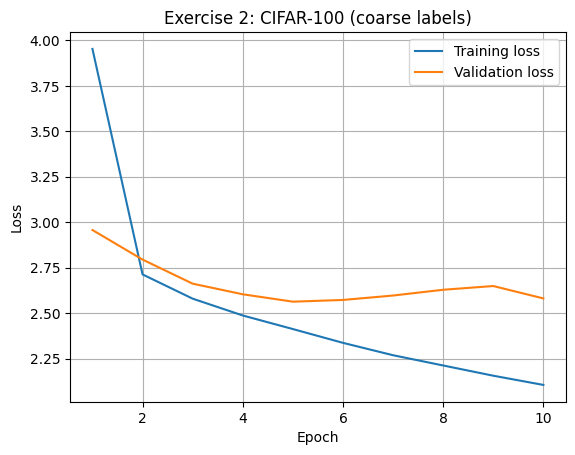

In [2]:
cifar = tf.keras.datasets.cifar100.load_data(label_mode="coarse")

(X_train_full, y_train_full), (X_test_full, y_test_full) = cifar
X_train, y_train = X_train_full[:5000] / 255.0, y_train_full[:5000]
X_test,  y_test  = X_test_full[:1000]  / 255.0, y_test_full[:1000]

tf.keras.utils.set_random_seed(42)

model_exercise_2 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(256, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(20, activation="softmax"),
])

model_exercise_2.compile(loss="sparse_categorical_crossentropy",
                         optimizer=keras.optimizers.Nadam(learning_rate=0.001),
                         metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model_exercise_2.fit(X_train, y_train, epochs=50, batch_size=128, validation_split=0.1, callbacks=[early_stop])

test_loss, test_acc = model_exercise_2.evaluate(X_test, y_test)
print(f"Q2.1 Test accuracy: {test_acc * 100:.2f}%")

epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training loss")
plt.plot(epochs, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 2: CIFAR-100 (coarse labels)")
plt.legend(); plt.grid(); plt.show()

## Exercise 3

In [3]:
from sklearn.preprocessing import StandardScaler

(X_train_full, y_train_full), (X_test_full, y_test_full) = keras.datasets.fashion_mnist.load_data()

X_train = X_train_full[:2000].reshape(-1, 784)
y_train = y_train_full[:2000]
X_test  = X_test_full[:400].reshape(-1, 784)
y_test  = y_test_full[:400]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

tf.keras.utils.set_random_seed(42)

model_exercise_3 = keras.Sequential([
    keras.Input(shape=(784,)),
    keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    keras.layers.AlphaDropout(0.1),
    keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    keras.layers.AlphaDropout(0.1),
    keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    keras.layers.AlphaDropout(0.1),
    keras.layers.Dense(10, activation="softmax"),
])

model_exercise_3.compile(loss="sparse_categorical_crossentropy",
                         optimizer=keras.optimizers.Nadam(learning_rate=0.001),
                         metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)

history = model_exercise_3.fit(X_train_scaled, y_train, epochs=50, batch_size=32,
                               validation_split=0.1, callbacks=[early_stop])

Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6006 - loss: 1.2060 - val_accuracy: 0.8050 - val_loss: 0.7526
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7500 - loss: 0.7043 - val_accuracy: 0.8200 - val_loss: 0.7377
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8106 - loss: 0.5708 - val_accuracy: 0.8100 - val_loss: 0.7147
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8244 - loss: 0.5051 - val_accuracy: 0.8300 - val_loss: 0.7029
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8272 - loss: 0.4674 - val_accuracy: 0.8200 - val_loss: 0.6939
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8589 - loss: 0.4033 - val_accuracy: 0.8100 - val_loss: 0.7750
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8711 - loss: 0.3554 - val_accuracy: 0.8400 - val_loss: 0.6972
Epoch 8/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8783 - loss: 0.3192 - val_accuracy: 0.8100 - val_loss:

### Q3.1

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 977us/step - accuracy: 0.8200 - loss: 0.6669
Test accuracy: 82.00%


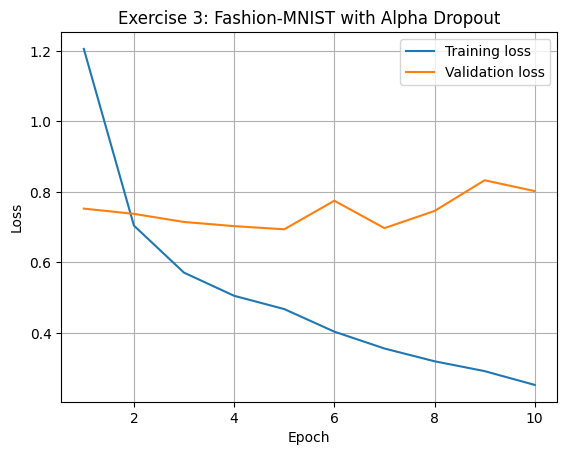

In [4]:
test_loss, test_acc = model_exercise_3.evaluate(X_test_scaled, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training loss")
plt.plot(epochs, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 3: Fashion-MNIST with Alpha Dropout")
plt.legend(); plt.grid(); plt.show()

### Q3.2

In [5]:
import numpy as np

y_probas = np.stack([model_exercise_3(X_test_scaled, training=True) for _ in range(20)])
y_proba = y_probas.mean(axis=0)

mc_acc = (y_proba.argmax(axis=1) == y_test).mean()
print(f"MC Dropout accuracy: {mc_acc * 100:.2f}%")

MC Dropout accuracy: 81.50%


## Exercise 4

In [6]:
import tensorflow_datasets as tfds
from tensorflow_datasets.image_classification import eurosat

# Original EuroSAT server (madm.dfki.de) is down -> use the authors' Zenodo copy (KI hjalp her)
rgb_config = eurosat.Eurosat.BUILDER_CONFIGS[0]
rgb_config.download_url = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
rgb_config.subdir = "EuroSAT_RGB"

(X_train, y_train), (X_test, y_test) = tfds.as_numpy(tfds.load(
    "eurosat/rgb",
    split=["train[:2000]", "train[2000:2500]"],
    as_supervised=True,
    shuffle_files=False,
    batch_size=-1,
))

X_train, X_test = X_train / 255.0, X_test / 255.0

tf.keras.utils.set_random_seed(42)

base_model = tf.keras.applications.MobileNetV2(include_top=False,
                                               weights="imagenet",
                                               input_shape=(64, 64, 3))

base_model.trainable = False

model_exercise_4 = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10, activation="softmax"),
])

model_exercise_4.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=0.001), metrics=["accuracy"])

history = model_exercise_4.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.1)

I0000 00:00:1792318619.700240 6729717 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
/var/folders/pg/5pkxwvy10bjffm8l5j7d4s7m0000gn/T/ipykernel_34029/72983370.py:21: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(include_top=False,


Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.5211 - loss: 1.4458 - val_accuracy: 0.7050 - val_loss: 0.8828
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7733 - loss: 0.6785 - val_accuracy: 0.7400 - val_loss: 0.7708
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8483 - loss: 0.4702 - val_accuracy: 0.7050 - val_loss: 0.7617
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8956 - loss: 0.3423 - val_accuracy: 0.7500 - val_loss: 0.7518
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9289 - loss: 0.2481 - val_accuracy: 0.7400 - val_loss: 0.7715


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7300 - loss: 0.8153
Q4.1 Test accuracy: 73.00%


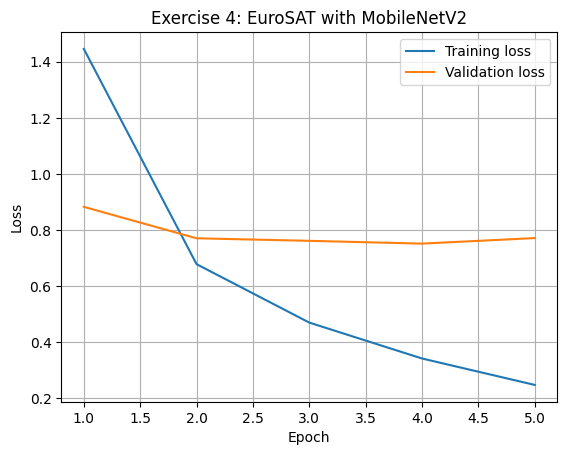

In [7]:
test_loss, test_acc = model_exercise_4.evaluate(X_test, y_test)
print(f"Q4.1 Test accuracy: {test_acc * 100:.2f}%")

epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training loss")
plt.plot(epochs, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 4: EuroSAT with MobileNetV2")
plt.legend(); plt.grid(); plt.show()

## Exercise 5

In [8]:
import tensorflow_datasets as tfds

(X_train, y_train), (X_test, y_test) = tfds.as_numpy(tfds.load(
    "kmnist",
    split=["train[:3000]", "test[:500]"],
    as_supervised=True,
    shuffle_files=False,
    batch_size=-1,
))

X_train, X_test = X_train / 255.0, X_test / 255.0

tf.keras.utils.set_random_seed(42)

model_exercise_5 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax"),
])

model_exercise_5.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(0.001), metrics=["accuracy"])

history = model_exercise_5.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.1)

Epoch 1/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5722 - loss: 1.2731 - val_accuracy: 0.7733 - val_loss: 0.6765
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8252 - loss: 0.5513 - val_accuracy: 0.8600 - val_loss: 0.4128
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8967 - loss: 0.3375 - val_accuracy: 0.8700 - val_loss: 0.3555
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9193 - loss: 0.2348 - val_accuracy: 0.9067 - val_loss: 0.3106
Epoch 5/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9456 - loss: 0.1623 - val_accuracy: 0.9000 - val_loss: 0.3085
Epoch 6/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9637 - loss: 0.1117 - val_accuracy: 0.9100 - val_loss: 0.3305
Epoch 7/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9700 - loss: 0.0893 - val_accuracy: 0.9133 - val_loss: 0.3064
Epoch 8/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9744 - loss: 0.0723 - val_accuracy: 0.9200 - v

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8260 - loss: 1.0635 
Q5.1 Test accuracy: 82.60%


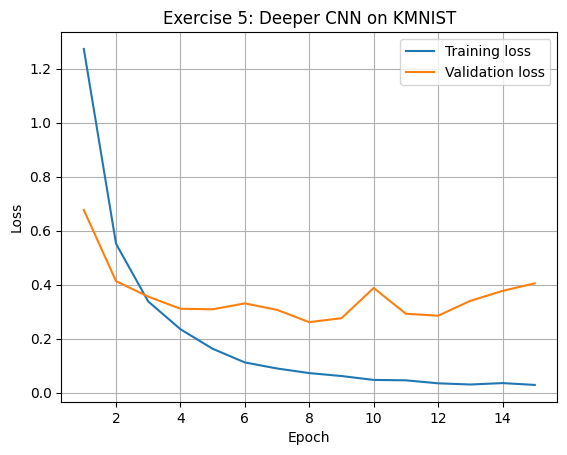

In [9]:
test_loss, test_acc = model_exercise_5.evaluate(X_test, y_test)
print(f"Q5.1 Test accuracy: {test_acc * 100:.2f}%")

epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training loss")
plt.plot(epochs, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 5: Deeper CNN on KMNIST")
plt.legend(); plt.grid(); plt.show()

## Exercise 6

In [10]:
(X_train, y_train), (X_test, y_test) = tfds.as_numpy(tfds.load(
    "kmnist",
    split=["train[:3000]", "test[:500]"],
    as_supervised=True,
    shuffle_files=False,
    batch_size=-1,
))

X_train, X_test = X_train / 255.0, X_test / 255.0

tf.keras.utils.set_random_seed(42)

model_exercise_6 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.25),
    keras.layers.Dense(10, activation="softmax"),
])

model_exercise_6.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.SGD(momentum=0.9, learning_rate=0.01), metrics=["accuracy"])

history = model_exercise_6.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.1)

Epoch 1/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3856 - loss: 1.7607 - val_accuracy: 0.6867 - val_loss: 1.0288
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7030 - loss: 0.9246 - val_accuracy: 0.7633 - val_loss: 0.7093
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7959 - loss: 0.6459 - val_accuracy: 0.8233 - val_loss: 0.5397
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8622 - loss: 0.4543 - val_accuracy: 0.8367 - val_loss: 0.4775
Epoch 5/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8922 - loss: 0.3533 - val_accuracy: 0.8667 - val_loss: 0.3875
Epoch 6/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8996 - loss: 0.3082 - val_accuracy: 0.8867 - val_loss: 0.3757
Epoch 7/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9122 - loss: 0.2466 - val_accuracy: 0.9033 - val_loss: 0.3668
Epoch 8/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9389 - loss: 0.1882 - val_accuracy: 0.8833 - val_loss:

### Q6.1

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7900 - loss: 0.8052 
Q6.1 Test accuracy: 79.00%


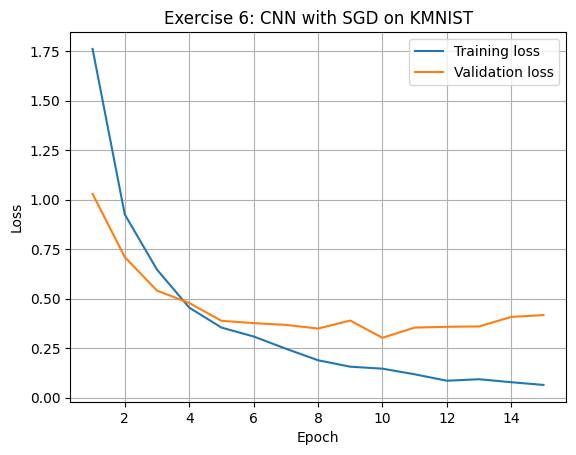

In [11]:
test_loss, test_acc = model_exercise_6.evaluate(X_test, y_test)
print(f"Q6.1 Test accuracy: {test_acc * 100:.2f}%")

epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training loss")
plt.plot(epochs, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 6: CNN with SGD on KMNIST")
plt.legend(); plt.grid(); plt.show()

### Q6.2

In [12]:
tf.keras.utils.set_random_seed(42)

y_probas = np.stack([model_exercise_6(X_test, training=True) for _ in range(20)])

y_proba = y_probas.mean(axis=0)
mc_acc = (y_proba.argmax(axis=1) == y_test).mean()
print(f"Q6.2 MC Dropout accuracy: {mc_acc * 100:.2f}%")

Q6.2 MC Dropout accuracy: 78.80%


### Q6.3

In [13]:
# Q6.3: epistemic uncertainty
var_per_class = y_probas.var(axis=0)
var_per_sample = var_per_class.mean(axis=1)
uncertainty = var_per_sample.mean()
print(f"Q6.3 Average epistemic uncertainty: {uncertainty:.3f}")

Q6.3 Average epistemic uncertainty: 0.006
